In [ ]:

# ============================================================
# BLOCK 1 - IMPORTS
# ============================================================

import os
import gc
import json
import random
import math
import time
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    DataCollatorForSeq2Seq,
    get_linear_schedule_with_warmup,
)

from peft import (
    LoraConfig,
    PeftModel,
    prepare_model_for_kbit_training,
    get_peft_model,
)

from torch.utils.data import Dataset, DataLoader

from nltk.translate.meteor_score import meteor_score
import nltk

warnings.filterwarnings("ignore")

# ============================================================
# BLOCK 2 - CONFIGURATION
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-Coder-3B-Instruct"

OUTPUT_DIR = "./outputs/qwen-commit-lora"

# Dataset options:
# "hf"    = Hugging Face dataset
# "local" = local CSV / XLSX / JSON / JSONL / Parquet

DATA_SOURCE = "hf"

HF_DATASET_NAME = "Maxscha/commitbench"

LOCAL_DATA_PATH = "./data/CommitBench.csv"

# Set these after inspecting the dataset columns.
# None means automatic column detection.
DIFF_COLUMN = "diff"
MESSAGE_COLUMN = "message"

# If automatic detection fails, change these manually.
# Examples:
# DIFF_COLUMN = "diff"
# MESSAGE_COLUMN = "message"

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------

SEED = 42

TRAIN_RATIO = 0.80
VALIDATION_RATIO = 0.10
TEST_RATIO = 0.10

NUM_EPOCHS = 10

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01

BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8

MAX_INPUT_LENGTH = 768
MAX_TARGET_LENGTH = 192

WARMUP_RATIO = 0.05

MAX_GRAD_NORM = 1.0

EARLY_STOPPING_PATIENCE = 2

# ------------------------------------------------------------
# QLoRA CONFIGURATION
# ------------------------------------------------------------

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05

# ------------------------------------------------------------
# GENERATION CONFIGURATION
# ------------------------------------------------------------

MAX_NEW_TOKENS = 128

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


Device: cuda
GPU: NVIDIA GeForce RTX 3070 Ti Laptop GPU
VRAM: 8.0 GB


In [2]:

# ============================================================
# BLOCK 3 - DATASET LOADING
# ============================================================

def load_local_dataset(path):
    extension = os.path.splitext(path)[1].lower()

    if extension == ".csv":
        return pd.read_csv(path)

    elif extension in [".xlsx", ".xls"]:
        return pd.read_excel(path)

    elif extension == ".json":
        return pd.read_json(path)

    elif extension == ".jsonl":
        return pd.read_json(path, lines=True)

    elif extension == ".parquet":
        return pd.read_parquet(path)

    else:
        raise ValueError(
            f"Unsupported dataset format: {extension}"
        )


def load_huggingface_dataset(dataset_name):
    print(f"Loading Hugging Face dataset: {dataset_name}")

    dataset = load_dataset(dataset_name)

    # Prefer train split if available
    if "train" in dataset:
        df = dataset["train"].to_pandas()

    else:
        split_name = list(dataset.keys())[0]
        df = dataset[split_name].to_pandas()

    return df


def load_raw_dataset():
    if DATA_SOURCE == "hf":
        df = load_huggingface_dataset(
            HF_DATASET_NAME
        )

    elif DATA_SOURCE == "local":
        df = load_local_dataset(
            LOCAL_DATA_PATH
        )

    else:
        raise ValueError(
            "DATA_SOURCE must be 'hf' or 'local'"
        )

    print("\nDataset loaded successfully.")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    return df


# ============================================================
# BLOCK 4 - COLUMN DETECTION
# ============================================================

def detect_column(df, manual_column, candidates):
    if manual_column is not None:
        if manual_column not in df.columns:
            raise ValueError(
                f"Column '{manual_column}' not found.\n"
                f"Available columns: {df.columns.tolist()}"
            )

        return manual_column

    normalized_columns = {
        str(column).lower().replace("_", "").replace(" ", ""):
        column
        for column in df.columns
    }

    for candidate in candidates:
        normalized_candidate = (
            candidate.lower()
            .replace("_", "")
            .replace(" ", "")
        )

        if normalized_candidate in normalized_columns:
            return normalized_columns[normalized_candidate]

    return None


def identify_dataset_columns(df):
    diff_candidates = [
        "diff",
        "code_diff",
        "patch",
        "commit_diff",
        "changes",
        "Diff",
        "Code Diff",
        "diff_text",
        "diff_content",
        "diffs",
    ]

    message_candidates = [
        "message",
        "commit_message",
        "commitmsg",
        "msg",
        "subject",
        "target",
        "summary",
        "Commit Message",
        "commit_message_text",
    ]

    diff_col = detect_column(
        df,
        DIFF_COLUMN,
        diff_candidates
    )

    message_col = detect_column(
        df,
        MESSAGE_COLUMN,
        message_candidates
    )

    print("\nDetected columns:")
    print("Diff column:", diff_col)
    print("Message column:", message_col)

    if diff_col is None or message_col is None:
        print("\nAutomatic detection failed.")
        print("Dataset columns:")
        print(df.columns.tolist())

        raise ValueError(
            "Set DIFF_COLUMN and MESSAGE_COLUMN "
            "manually in the configuration."
        )

    return diff_col, message_col


# ============================================================
# BLOCK 5 - CLEAN DATASET
# ============================================================

def clean_dataset(df):
    diff_col, message_col = identify_dataset_columns(df)

    df = df[[diff_col, message_col]].copy()

    df.columns = [
        "diff",
        "commit_message"
    ]

    # Convert values to strings
    df["diff"] = df["diff"].fillna("").astype(str)
    df["commit_message"] = (
        df["commit_message"]
        .fillna("")
        .astype(str)
    )

    # Remove empty examples
    df = df[
        (df["diff"].str.strip() != "")
        &
        (df["commit_message"].str.strip() != "")
    ]

    # Remove placeholder values
    df = df[
        ~df["commit_message"].str.lower().isin(
            ["nan", "none", "null"]
        )
    ]

    # Remove duplicated examples
    df = df.drop_duplicates(
        subset=["diff", "commit_message"]
    )

    # Clean whitespace
    df["diff"] = df["diff"].str.strip()
    df["commit_message"] = (
        df["commit_message"].str.strip()
    )

    df = df.reset_index(drop=True)

    print("\nCleaned dataset:")
    print("Rows:", len(df))
    print("\nExample:")
    print(df.iloc[0])

    return df


# ============================================================
# BLOCK 6 - TRAIN / VALIDATION / TEST SPLIT
# ============================================================

def split_dataset(df):
    train_df, temporary_df = train_test_split(
        df,
        test_size=(1 - TRAIN_RATIO),
        random_state=SEED,
        shuffle=True
    )

    relative_test_size = (
        TEST_RATIO /
        (VALIDATION_RATIO + TEST_RATIO)
    )

    validation_df, test_df = train_test_split(
        temporary_df,
        test_size=relative_test_size,
        random_state=SEED,
        shuffle=True
    )

    train_df = train_df.reset_index(drop=True)
    validation_df = validation_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    print("\nDataset split:")
    print("Train:", len(train_df))
    print("Validation:", len(validation_df))
    print("Test:", len(test_df))

    return train_df, validation_df, test_df


In [3]:

# ============================================================
# BLOCK 7 - TOKENIZER
# ============================================================

print("\nLoading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

# Qwen may not define a separate padding token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("Tokenizer loaded.")
print("Vocabulary:", len(tokenizer))


# ============================================================
# BLOCK 8 - 4-BIT QUANTIZATION
# ============================================================

if DEVICE == "cuda":

    compute_dtype = torch.float16

    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype
    )

else:
    quantization_config = None


# ============================================================
# BLOCK 9 - LOAD QWEN MODEL
# ============================================================

print("\nLoading Qwen model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quantization_config,
    device_map="auto" if DEVICE == "cuda" else None,
    torch_dtype=(
        torch.float16
        if DEVICE == "cuda"
        else torch.float32
    ),
    trust_remote_code=True
)

model.config.use_cache = False

# Gradient checkpointing reduces VRAM usage
model.gradient_checkpointing_enable()

print("Base model loaded.")


# ============================================================
# BLOCK 10 - PREPARE MODEL FOR QLORA
# ============================================================

if DEVICE == "cuda":
    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=True
    )


# ============================================================
# BLOCK 11 - LORA CONFIGURATION
# ============================================================

lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type="CAUSAL_LM",

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

print("\nQwen is ready for fine-tuning.")



Loading tokenizer...
Tokenizer loaded.
Vocabulary: 151665

Loading Qwen model...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 2/2 [00:10<00:00,  5.38s/it]


Base model loaded.
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607

Qwen is ready for fine-tuning.


In [4]:

# ============================================================
# FIX - DEFINE PROMPT FUNCTION
# ============================================================

def create_prompt(diff):
    return (
        "You are an expert software developer.\n"
        "Write one concise, informative Git commit "
        "message summarizing the code changes.\n"
        "Return only the commit message.\n\n"
        "Code diff:\n"
        f"{diff}\n\n"
        "Commit message:"
    )

print("create_prompt() defined successfully.")

create_prompt() defined successfully.


In [ ]:

# ============================================================
# BLOCK 12 - LOAD PRE-PROCESSED SPLITS
# ============================================================

import json
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed"
)

# Dataset limits
MAX_TRAIN_SAMPLES = 9600
MAX_VALIDATION_SAMPLES = 1200
MAX_TEST_SAMPLES = 1200




# ============================================================
# LOAD JSONL FILES
# ============================================================

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return pd.DataFrame([
            json.loads(line)
            for line in f
            if line.strip()
        ])


# ============================================================
# PREPARE DATAFRAME
# ============================================================

def prepare_dataframe(df):

    # Map dataset columns
    df = df[["diff", "message"]].copy()

    df.rename(
        columns={"message": "commit_message"},
        inplace=True
    )

    # Clean missing values
    df["diff"] = df["diff"].fillna("").astype(str)

    df["commit_message"] = (
        df["commit_message"]
        .fillna("")
        .astype(str)
    )

    # Remove empty examples
    df = df[
        (df["diff"].str.strip() != "") &
        (df["commit_message"].str.strip() != "")
    ].copy()

    # Remove duplicates
    df.drop_duplicates(
        subset=["diff", "commit_message"],
        inplace=True
    )

    # Reset index
    df.reset_index(drop=True, inplace=True)

    return df


# ============================================================
# LOAD AND CLEAN ALL DATASETS
# ============================================================

train_df = prepare_dataframe(
    load_jsonl(DATA_DIR / "train.jsonl")
)

validation_df = prepare_dataframe(
    load_jsonl(DATA_DIR / "validation.jsonl")
)

test_df = prepare_dataframe(
    load_jsonl(DATA_DIR / "test.jsonl")
)


# ============================================================
# LIMIT TRAINING DATA
# ============================================================

train_df = train_df.sample(
    n=min(MAX_TRAIN_SAMPLES, len(train_df)),
    random_state=42
).reset_index(drop=True)


# ============================================================
# LIMIT VALIDATION DATA
# ============================================================

validation_df = validation_df.sample(
    n=min(MAX_VALIDATION_SAMPLES, len(validation_df)),
    random_state=42
).reset_index(drop=True)


# ============================================================
# LIMIT TESTING DATA
# ============================================================

test_df = test_df.sample(
    n=min(MAX_TEST_SAMPLES, len(test_df)),
    random_state=42
).reset_index(drop=True)


# ============================================================
# DISPLAY DATASET INFORMATION
# ============================================================

print("Dataset loaded and cleaned successfully.")

print("Training examples:", len(train_df))
print("Validation examples:", len(validation_df))
print("Testing examples:", len(test_df))

print("\nColumns:")
print(train_df.columns.tolist())

print("\nExample:")
print(train_df.iloc[0])


# ============================================================
# BLOCK 13 - TOKENIZATION
# ============================================================

def tokenize_example(diff, commit_message):

    prompt = create_prompt(diff)

    # Tokenize prompt independently
    prompt_tokens = tokenizer(
        prompt,
        add_special_tokens=True,
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    )

    # Tokenize target independently
    target_tokens = tokenizer(
        commit_message,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_TARGET_LENGTH - 1
    )

    prompt_ids = prompt_tokens["input_ids"]
    target_ids = target_tokens["input_ids"]

    # Add EOS to target
    target_ids = target_ids + [
        tokenizer.eos_token_id
    ]

    # Input = prompt + target
    input_ids = prompt_ids + target_ids

    # Ignore prompt when calculating loss
    labels = (
        [-100] * len(prompt_ids)
        +
        target_ids
    )

    attention_mask = [1] * len(input_ids)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


# ============================================================
# BLOCK 14 - PYTORCH DATASET
# ============================================================

class CommitMessageDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        return tokenize_example(
            row["diff"],
            row["commit_message"]
        )


# ============================================================
# BLOCK 15 - CUSTOM COLLATE FUNCTION
# ============================================================

def collate_fn(batch):

    max_length = max(
        len(item["input_ids"])
        for item in batch
    )

    input_ids = []
    attention_masks = []
    labels = []

    for item in batch:

        padding_length = (
            max_length - len(item["input_ids"])
        )

        input_ids.append(
            item["input_ids"]
            +
            [tokenizer.pad_token_id] * padding_length
        )

        attention_masks.append(
            item["attention_mask"]
            +
            [0] * padding_length
        )

        labels.append(
            item["labels"]
            +
            [-100] * padding_length
        )

    return {
        "input_ids": torch.tensor(
            input_ids,
            dtype=torch.long
        ),

        "attention_mask": torch.tensor(
            attention_masks,
            dtype=torch.long
        ),

        "labels": torch.tensor(
            labels,
            dtype=torch.long
        )
    }


# ============================================================
# BLOCK 16 - CREATE DATA LOADERS
# ============================================================

train_dataset = CommitMessageDataset(train_df)

validation_dataset = CommitMessageDataset(validation_df)

test_dataset = CommitMessageDataset(test_df)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)


# ============================================================
# DISPLAY DATALOADER INFORMATION
# ============================================================

print("\nDataLoaders created successfully.")

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


Dataset loaded and cleaned successfully.
Training examples: 6000
Validation examples: 1200
Testing examples: 1200

Columns:
['diff', 'commit_message']

Example:
diff              diff --git a/firebirdsql/fbcore.py b/firebirds...
commit_message     restart transaction when commit() and rollback()
Name: 0, dtype: object

DataLoaders created successfully.
Training batches: 6000
Validation batches: 1200
Testing batches: 1200


In [6]:

# ============================================================
# BLOCK 17 - OPTIMIZER
# ============================================================

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# BLOCK 18 - LEARNING RATE SCHEDULER
# ============================================================

updates_per_epoch = math.ceil(
    len(train_loader) /
    GRADIENT_ACCUMULATION_STEPS
)

total_training_steps = (
    updates_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Total optimizer updates:", total_training_steps)
print("Warmup updates:", warmup_steps)


# ============================================================
# BLOCK 19 - MOVE BATCH TO DEVICE
# ============================================================

def move_batch_to_device(batch):
    return {
        key: value.to(DEVICE)
        for key, value in batch.items()
    }


# ============================================================
# BLOCK 20 - TRAINING EPOCH
# ============================================================

def train_one_epoch(epoch):

    model.train()

    total_loss = 0.0

    optimizer.zero_grad(set_to_none=True)

    progress_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch}"
    )

    number_of_batches = len(train_loader)

    for step, batch in enumerate(progress_bar):

        batch = move_batch_to_device(batch)

        outputs = model(**batch)

        loss = outputs.loss

        # Normalize for gradient accumulation
        loss_for_backward = (
            loss / GRADIENT_ACCUMULATION_STEPS
        )

        loss_for_backward.backward()

        total_loss += loss.item()

        # Update weights after accumulation
        is_update_step = (
            (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or
            (step + 1) == number_of_batches
        )

        if is_update_step:

            torch.nn.utils.clip_grad_norm_(
                trainable_parameters,
                MAX_GRAD_NORM
            )

            optimizer.step()
            scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        progress_bar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "lr": f"{scheduler.get_last_lr()[0]:.2e}"
        })

        del outputs
        del batch

    average_loss = (
        total_loss / len(train_loader)
    )

    return average_loss


# ============================================================
# BLOCK 21 - VALIDATION
# ============================================================

@torch.no_grad()
def evaluate_loss(loader):

    model.eval()

    total_loss = 0.0

    progress_bar = tqdm(
        loader,
        desc="Validation"
    )

    for batch in progress_bar:

        batch = move_batch_to_device(batch)

        outputs = model(**batch)

        total_loss += outputs.loss.item()

        del outputs
        del batch

    average_loss = (
        total_loss / len(loader)
    )

    perplexity = math.exp(
        min(average_loss, 20)
    )

    return average_loss, perplexity


Total optimizer updates: 7500
Warmup updates: 375


In [7]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

# ============================================================
# EVALUATION - GENERATION METRICS
# BLEU, ROUGE-1, ROUGE-2, ROUGE-L, METEOR
# ============================================================

import torch
import numpy as np

from tqdm.auto import tqdm
from sacrebleu import corpus_bleu
from rouge_score import rouge_scorer
from nltk.translate.meteor_score import meteor_score


def evaluate_generation_metrics(
    validation_loader,
    max_samples=300,
    max_new_tokens=128
):

    print("\nCalculating generation metrics...")

    model.eval()

    predictions = []
    references = []

    device = next(model.parameters()).device

    samples_evaluated = 0

    # --------------------------------------------------------
    # ROUGE SCORER
    # --------------------------------------------------------

    rouge = rouge_scorer.RougeScorer(
        ["rouge1", "rouge2", "rougeL"],
        use_stemmer=True
    )

    # --------------------------------------------------------
    # GENERATION
    # --------------------------------------------------------

    with torch.no_grad():

        progress_bar = tqdm(
            validation_loader,
            desc="Generating commit messages"
        )

        for batch in progress_bar:

            input_ids = batch["input_ids"]
            attention_mask = batch["attention_mask"]
            labels = batch["labels"]

            batch_size = input_ids.size(0)

            for i in range(batch_size):

                if samples_evaluated >= max_samples:
                    break

                # ------------------------------------------------
                # FIND THE START OF THE TARGET MESSAGE
                # ------------------------------------------------

                target_positions = torch.where(
                    labels[i] != -100
                )[0]

                if len(target_positions) == 0:
                    continue

                prompt_length = target_positions[0].item()

                # Input contains prompt + reference message.
                # We only provide the prompt to generate().
                prompt_ids = input_ids[
                    i, :prompt_length
                ].unsqueeze(0).to(device)

                prompt_mask = attention_mask[
                    i, :prompt_length
                ].unsqueeze(0).to(device)

                # ------------------------------------------------
                # GENERATE COMMIT MESSAGE
                # ------------------------------------------------

                generated_ids = model.generate(
                    input_ids=prompt_ids,
                    attention_mask=prompt_mask,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    num_beams=1,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )

                # Remove the input prompt from generated output.
                generated_tokens = generated_ids[
                    0, prompt_length:
                ]

                # ------------------------------------------------
                # DECODE PREDICTION
                # ------------------------------------------------

                prediction = tokenizer.decode(
                    generated_tokens,
                    skip_special_tokens=True
                ).strip()

                # ------------------------------------------------
                # DECODE REFERENCE
                # ------------------------------------------------

                reference_ids = labels[i]

                # Remove -100 values used for loss masking.
                reference_ids = reference_ids[
                    reference_ids != -100
                ]

                reference = tokenizer.decode(
                    reference_ids,
                    skip_special_tokens=True
                ).strip()

                # ------------------------------------------------
                # STORE RESULTS
                # ------------------------------------------------

                if prediction and reference:

                    predictions.append(prediction)
                    references.append(reference)

                    samples_evaluated += 1

                    progress_bar.set_postfix(
                        samples=samples_evaluated
                    )

            if samples_evaluated >= max_samples:
                break

    # --------------------------------------------------------
    # RESTORE MODEL TRAINING MODE
    # --------------------------------------------------------

    model.train()

    # --------------------------------------------------------
    # CHECK RESULTS
    # --------------------------------------------------------

    if len(predictions) == 0:

        raise ValueError(
            "No valid predictions were generated. "
            "Check your validation dataset and labels."
        )

    print(
        f"\nSuccessfully evaluated "
        f"{len(predictions)} examples."
    )

    # --------------------------------------------------------
    # BLEU
    # SacreBLEU returns a score from 0 to 100.
    # --------------------------------------------------------

    bleu = corpus_bleu(
        predictions,
        [references]
    ).score

    # --------------------------------------------------------
    # ROUGE
    # Scores are between 0 and 1.
    # --------------------------------------------------------

    rouge1_scores = []
    rouge2_scores = []
    rougeL_scores = []

    for prediction, reference in zip(
        predictions,
        references
    ):

        scores = rouge.score(
            reference,
            prediction
        )

        rouge1_scores.append(
            scores["rouge1"].fmeasure
        )

        rouge2_scores.append(
            scores["rouge2"].fmeasure
        )

        rougeL_scores.append(
            scores["rougeL"].fmeasure
        )

    rouge1 = float(np.mean(rouge1_scores))
    rouge2 = float(np.mean(rouge2_scores))
    rougeL = float(np.mean(rougeL_scores))

    # --------------------------------------------------------
    # METEOR
    # Score is between 0 and 1.
    # --------------------------------------------------------

    meteor_scores = []

    for prediction, reference in zip(
        predictions,
        references
    ):

        prediction_tokens = prediction.split()
        reference_tokens = reference.split()

        score = meteor_score(
            [reference_tokens],
            prediction_tokens
        )

        meteor_scores.append(score)

    meteor = float(np.mean(meteor_scores))

    # --------------------------------------------------------
    # RESULTS
    # --------------------------------------------------------

    results = {
        "bleu": float(bleu),
        "rouge1": rouge1,
        "rouge2": rouge2,
        "rougeL": rougeL,
        "meteor": meteor
    }

    print("\n" + "=" * 50)
    print("GENERATION EVALUATION RESULTS")
    print("=" * 50)

    print(f"BLEU:       {bleu:.4f}")
    print(f"ROUGE-1:    {rouge1:.4f}")
    print(f"ROUGE-2:    {rouge2:.4f}")
    print(f"ROUGE-L:    {rougeL:.4f}")
    print(f"METEOR:     {meteor:.4f}")

    print("=" * 50)

    return results


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ASUSD\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ASUSD\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:
# ============================================================
# FIXED TRAINING SUBSET FOR GENERATION EVALUATION
# ============================================================

from torch.utils.data import DataLoader, Subset

TRAIN_GENERATION_SAMPLES = 300

train_eval_dataset = Subset(
    train_loader.dataset,
    range(
        min(
            TRAIN_GENERATION_SAMPLES,
            len(train_loader.dataset)
        )
    )
)

train_metrics_loader = DataLoader(
    train_eval_dataset,
    batch_size=train_loader.batch_size,
    shuffle=False,
    collate_fn=train_loader.collate_fn
)

print(
    "Training generation evaluation samples:",
    len(train_eval_dataset)
)

Training generation evaluation samples: 300


In [9]:

# ============================================================
# BLOCK 22 - TRAINING HISTORY
# ============================================================

history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_perplexity": [],

    "train_rouge1": [],
    "train_rouge2": [],
    "train_rougeL": [],

    "validation_bleu": [],
    "validation_rouge1": [],
    "validation_rouge2": [],
    "validation_rougeL": [],
    "validation_meteor": []
}

best_validation_rougeL = -float("inf")
epochs_without_improvement = 0


# ============================================================
# BLOCK 23 - MAIN TRAINING LOOP
# Early Stopping Based on Validation ROUGE-L
# ============================================================

print("\nStarting QLoRA fine-tuning...\n")

# Best ROUGE-L score
best_validation_rougeL = -float("inf")

for epoch in range(1, NUM_EPOCHS + 1):

    start_time = time.time()

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print("=" * 60)

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss = train_one_epoch(epoch)


    # --------------------------------------------------------
    # TRAINING GENERATION METRICS
    # --------------------------------------------------------

    train_metrics = evaluate_generation_metrics(
        train_metrics_loader,
        max_samples=300
    )

    train_rouge1 = train_metrics["rouge1"]
    train_rouge2 = train_metrics["rouge2"]
    train_rougeL = train_metrics["rougeL"]

    history["train_rouge1"].append(train_rouge1)
    history["train_rouge2"].append(train_rouge2)
    history["train_rougeL"].append(train_rougeL)


    print("\nTraining generation metrics:")
    print(f"ROUGE-1: {train_rouge1:.4f}")
    print(f"ROUGE-2: {train_rouge2:.4f}")
    print(f"ROUGE-L: {train_rougeL:.4f}")

    # --------------------------------------------------------
    # VALIDATION LOSS AND PERPLEXITY
    # --------------------------------------------------------

    validation_loss, validation_perplexity = (
        evaluate_loss(validation_loader)
    )

    # --------------------------------------------------------
    # GENERATION METRICS
    # --------------------------------------------------------
    # Evaluate on a fixed validation subset.
    # Use the same examples and generation settings every epoch.
    #
    # Expected return format:
    # {
    #     "bleu": float,
    #     "rouge1": float,
    #     "rouge2": float,
    #     "rougeL": float,
    #     "meteor": float
    # }

    validation_metrics = evaluate_generation_metrics(
        validation_loader,
        max_samples=300
    )

    validation_bleu = validation_metrics["bleu"]
    validation_rouge1 = validation_metrics["rouge1"]
    validation_rouge2 = validation_metrics["rouge2"]
    validation_rougeL = validation_metrics["rougeL"]
    validation_meteor = validation_metrics["meteor"]

    elapsed_time = time.time() - start_time

    # --------------------------------------------------------
    # UPDATE HISTORY
    # --------------------------------------------------------

    history["train_loss"].append(train_loss)

    history["validation_loss"].append(
        validation_loss
    )

    history["validation_perplexity"].append(
        validation_perplexity
    )

    history["validation_bleu"].append(
        validation_bleu
    )

    history["validation_rouge1"].append(
        validation_rouge1
    )

    history["validation_rouge2"].append(
        validation_rouge2
    )

    history["validation_rougeL"].append(
        validation_rougeL
    )

    history["validation_meteor"].append(
        validation_meteor
    )

    # --------------------------------------------------------
    # PRINT EPOCH RESULTS
    # --------------------------------------------------------

    print("\nEpoch results:")
    print("-" * 40)

    print(f"Train loss:              {train_loss:.4f}")
    print(f"Validation loss:         {validation_loss:.4f}")
    print(f"Validation perplexity:   {validation_perplexity:.4f}")

    print("\nGeneration metrics:")
    print(f"BLEU:                    {validation_bleu:.4f}")
    print(f"ROUGE-1:                 {validation_rouge1:.4f}")
    print(f"ROUGE-2:                 {validation_rouge2:.4f}")
    print(f"ROUGE-L:                 {validation_rougeL:.4f}")
    print(f"METEOR:                  {validation_meteor:.4f}")

    print(f"\nTime: {elapsed_time / 60:.2f} minutes")

    # --------------------------------------------------------
    # SAVE BEST MODEL BASED ON ROUGE-L
    # --------------------------------------------------------

    if validation_rougeL > best_validation_rougeL:

        best_validation_rougeL = validation_rougeL
        epochs_without_improvement = 0

        print("\nNew best validation ROUGE-L!")
        print("Saving best model...")

        # Save LoRA adapter
        model.save_pretrained(
            OUTPUT_DIR,
            safe_serialization=True
        )

        # Save tokenizer
        tokenizer.save_pretrained(
            OUTPUT_DIR
        )

        # Save training configuration and best metrics
        training_config = {
            "base_model": MODEL_NAME,
            "best_epoch": epoch,
            "best_validation_rougeL": best_validation_rougeL,
            "best_validation_loss": validation_loss,
            "best_validation_perplexity": validation_perplexity,
            "validation_bleu": validation_bleu,
            "validation_rouge1": validation_rouge1,
            "validation_rouge2": validation_rouge2,
            "validation_rougeL": validation_rougeL,
            "validation_meteor": validation_meteor,
            "learning_rate": LEARNING_RATE,
            "lora_r": LORA_R,
            "lora_alpha": LORA_ALPHA,
            "max_input_length": MAX_INPUT_LENGTH,
            "max_target_length": MAX_TARGET_LENGTH
        }

        with open(
            os.path.join(
                OUTPUT_DIR,
                "training_config.json"
            ),
            "w",
            encoding="utf-8"
        ) as file:

            json.dump(
                training_config,
                file,
                indent=4
            )

        print("Best adapter saved successfully.")

    else:

        epochs_without_improvement += 1

        print("\nValidation ROUGE-L did not improve.")

        print(
            f"Epochs without improvement: "
            f"{epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print("\n" + "=" * 60)
        print("EARLY STOPPING TRIGGERED")
        print("=" * 60)

        print(
            "Validation ROUGE-L did not improve for "
            f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
        )

        break

    # --------------------------------------------------------
    # FREE MEMORY
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# TRAINING COMPLETED
# ============================================================

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best validation ROUGE-L: "
    f"{best_validation_rougeL:.4f}"
)

print("Adapter location:", OUTPUT_DIR)



Starting QLoRA fine-tuning...


EPOCH 1/10


Training Epoch 1: 100%|██████████| 6000/6000 [1:48:45<00:00,  1.09s/it, loss=3.4273, lr=4.74e-05]  



Calculating generation metrics...


Generating commit messages: 100%|█████████▉| 299/300 [05:58<00:01,  1.20s/it, samples=300]



Successfully evaluated 300 examples.

GENERATION EVALUATION RESULTS
BLEU:       1.9818
ROUGE-1:    0.2618
ROUGE-2:    0.0706
ROUGE-L:    0.2367
METEOR:     0.1182

Training generation metrics:
ROUGE-1: 0.2618
ROUGE-2: 0.0706
ROUGE-L: 0.2367


Validation: 100%|██████████| 1200/1200 [04:15<00:00,  4.69it/s]


... (31 outputs left out)

Validation: 100%|██████████| 1200/1200 [03:58<00:00,  5.02it/s]



Calculating generation metrics...


Generating commit messages:  25%|██▍       | 299/1200 [07:56<23:55,  1.59s/it, samples=300]  


Successfully evaluated 300 examples.

GENERATION EVALUATION RESULTS
BLEU:       2.5450
ROUGE-1:    0.2503
ROUGE-2:    0.0691
ROUGE-L:    0.2217
METEOR:     0.1315

Epoch results:
----------------------------------------
Train loss:              1.2829
Validation loss:         3.6065
Validation perplexity:   36.8379

Generation metrics:
BLEU:                    2.5450
ROUGE-1:                 0.2503
ROUGE-2:                 0.0691
ROUGE-L:                 0.2217
METEOR:                  0.1315

Time: 81.84 minutes

Validation ROUGE-L did not improve.
Epochs without improvement: 3/3

EARLY STOPPING TRIGGERED
Validation ROUGE-L did not improve for 3 consecutive epochs.

TRAINING COMPLETED
Best validation ROUGE-L: 0.2424
Adapter location: ./outputs/qwen-commit-lora


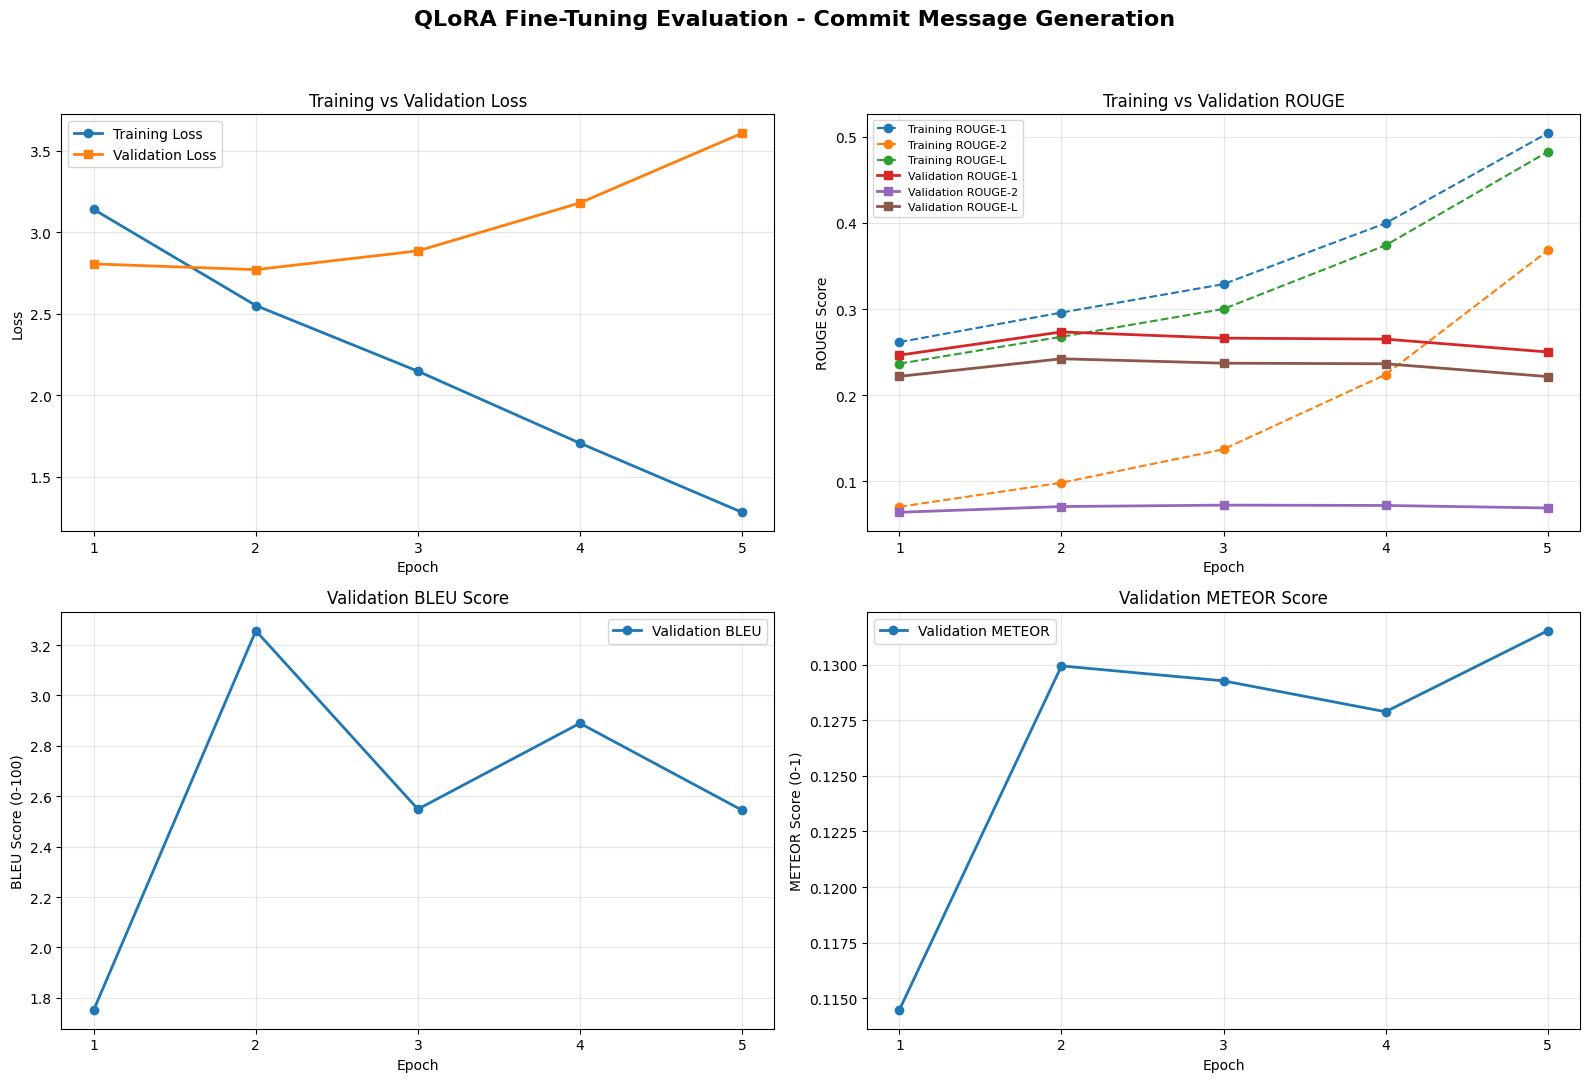

Figure saved as qwen_commit_generation_metrics.png


In [10]:

# ============================================================
# BLOCK 24 - TRAINING AND VALIDATION METRICS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# EPOCHS
# ------------------------------------------------------------

epochs = range(1, len(history["train_loss"]) + 1)

# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

fig.suptitle(
    "QLoRA Fine-Tuning Evaluation - Commit Message Generation",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# PLOT 1 - TRAINING AND VALIDATION LOSS
# ============================================================

ax = axes[0, 0]

ax.plot(
    epochs,
    history["train_loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

ax.plot(
    epochs,
    history["validation_loss"],
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

ax.set_title("Training vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

ax.set_xticks(list(epochs))
ax.grid(True, alpha=0.3)
ax.legend()

# ============================================================
# PLOT 2 - ROUGE METRICS (TRAINING VS VALIDATION)
# ============================================================

ax = axes[0, 1]

# Training ROUGE
ax.plot(
    epochs,
    history["train_rouge1"],
    marker="o",
    linestyle="--",
    label="Training ROUGE-1"
)

ax.plot(
    epochs,
    history["train_rouge2"],
    marker="o",
    linestyle="--",
    label="Training ROUGE-2"
)

ax.plot(
    epochs,
    history["train_rougeL"],
    marker="o",
    linestyle="--",
    label="Training ROUGE-L"
)

# Validation ROUGE
ax.plot(
    epochs,
    history["validation_rouge1"],
    marker="s",
    linewidth=2,
    label="Validation ROUGE-1"
)

ax.plot(
    epochs,
    history["validation_rouge2"],
    marker="s",
    linewidth=2,
    label="Validation ROUGE-2"
)

ax.plot(
    epochs,
    history["validation_rougeL"],
    marker="s",
    linewidth=2,
    label="Validation ROUGE-L"
)

ax.set_title("Training vs Validation ROUGE")
ax.set_xlabel("Epoch")
ax.set_ylabel("ROUGE Score")

ax.set_xticks(list(epochs))
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

# ============================================================
# PLOT 3 - VALIDATION BLEU
# ============================================================

ax = axes[1, 0]

ax.plot(
    epochs,
    history["validation_bleu"],
    marker="o",
    linewidth=2,
    label="Validation BLEU"
)

ax.set_title("Validation BLEU Score")
ax.set_xlabel("Epoch")
ax.set_ylabel("BLEU Score (0-100)")

ax.set_xticks(list(epochs))
ax.grid(True, alpha=0.3)
ax.legend()

# ============================================================
# PLOT 4 - VALIDATION METEOR
# ============================================================

ax = axes[1, 1]

ax.plot(
    epochs,
    history["validation_meteor"],
    marker="o",
    linewidth=2,
    label="Validation METEOR"
)

ax.set_title("Validation METEOR Score")
ax.set_xlabel("Epoch")
ax.set_ylabel("METEOR Score (0-1)")

ax.set_xticks(list(epochs))
ax.grid(True, alpha=0.3)
ax.legend()

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout(rect=[0, 0, 1, 0.95])

# ------------------------------------------------------------
# SAVE HIGH-RESOLUTION FIGURE
# ------------------------------------------------------------

plt.savefig(
    "qwen_commit_generation_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved as "
    "qwen_commit_generation_metrics.png"
)


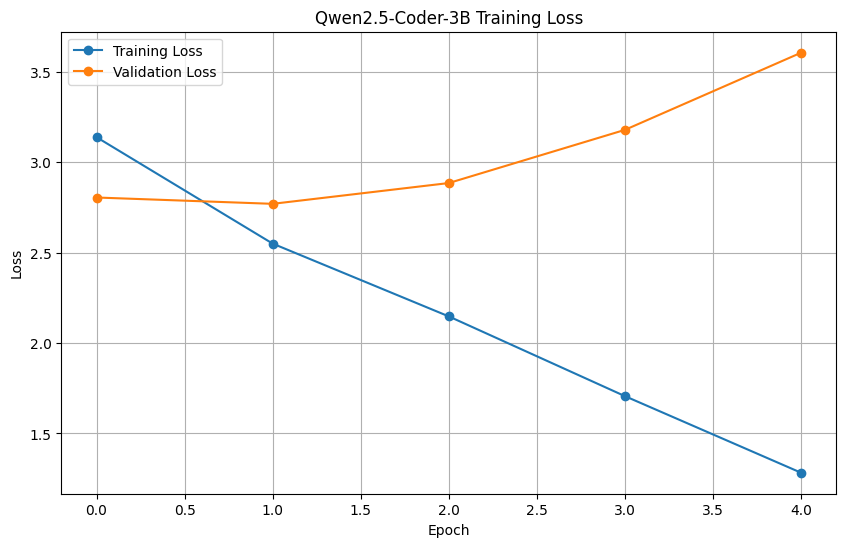

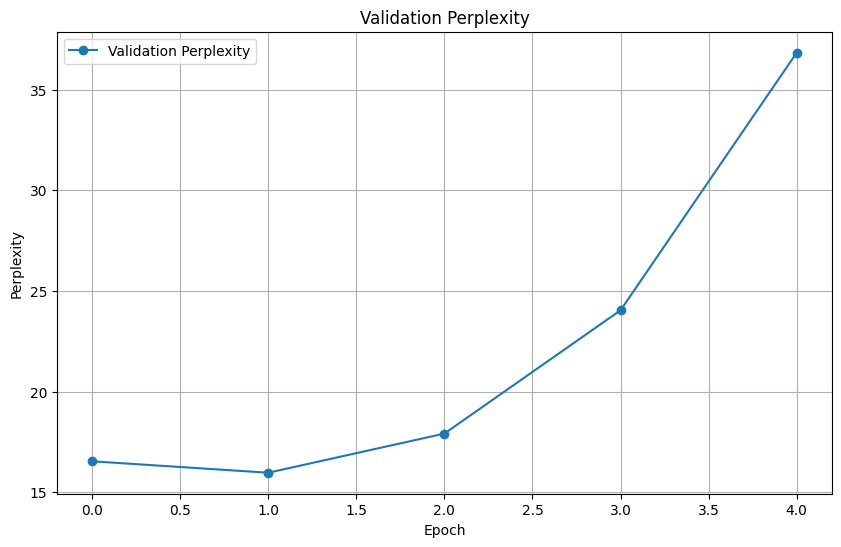

Training history saved.


In [11]:

# ============================================================
# BLOCK 24 - TRAINING LOSS PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history["validation_loss"],
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Qwen2.5-Coder-3B Training Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "training_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# BLOCK 25 - VALIDATION PERPLEXITY PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history["validation_perplexity"],
    label="Validation Perplexity",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Perplexity")
plt.title("Validation Perplexity")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "validation_perplexity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# BLOCK 26 - SAVE TRAINING HISTORY
# ============================================================

with open(
    os.path.join(
        OUTPUT_DIR,
        "training_history.json"
    ),
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        history,
        file,
        indent=4
    )

print("Training history saved.")


In [12]:

# ============================================================
# BLOCK 27 - RELOAD BEST ADAPTER
# ============================================================

print("\nReloading best adapter for testing...")

del model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quantization_config,
    device_map="auto" if DEVICE == "cuda" else None,
    torch_dtype=(
        torch.float16
        if DEVICE == "cuda"
        else torch.float32
    ),
    trust_remote_code=True
)

model = PeftModel.from_pretrained(
    base_model,
    OUTPUT_DIR,
    is_trainable=False
)

model.eval()
model.config.use_cache = True

print("Best adapter loaded.")



Reloading best adapter for testing...


Loading checkpoint shards: 100%|██████████| 2/2 [00:08<00:00,  4.43s/it]


Best adapter loaded.


In [13]:

# ============================================================
# BLOCK 28 - GENERATE COMMIT MESSAGE
# ============================================================

@torch.no_grad()
def generate_commit_message(diff):

    model.eval()

    prompt = create_prompt(diff)

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_INPUT_LENGTH
    )

    # Use the model's input device
    input_device = model.get_input_embeddings().weight.device

    inputs = {
        key: value.to(input_device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[1]

    generated = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        num_beams=1,
        repetition_penalty=1.05,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )

    # Decode only the newly generated tokens
    generated_tokens = generated[
        0,
        input_length:
    ]

    prediction = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    prediction = prediction.strip()

    return prediction


# ============================================================
# BLOCK 29 - TEST ONE EXAMPLE
# ============================================================

example_diff = test_df.iloc[0]["diff"]

example_reference = (
    test_df.iloc[0]["commit_message"]
)

example_prediction = generate_commit_message(
    example_diff
)

print("\nExample diff:")
print(example_diff[:1000])

print("\nReference commit message:")
print(example_reference)

print("\nGenerated commit message:")
print(example_prediction)



Example diff:
diff --git a/jsonrpc/manager.py b/jsonrpc/manager.py
index <HASH>..<HASH> 100644
--- a/jsonrpc/manager.py
+++ b/jsonrpc/manager.py
@@ -109,13 +109,14 @@ class JSONRPCResponseManager(object):
                 except JSONRPCDispatchException as e:
                     output = response(error=e.error._data)
                 except Exception as e:
-                    logger.exception("API Exception:")
-
                     data = {
                         "type": e.__class__.__name__,
                         "args": e.args,
                         "message": str(e),
                     }
+
+                    logger.exception("API Exception: {0}".format(data))
+
                     if isinstance(e, TypeError) and is_invalid_params(
                             method, *request.args, **request.kwargs):
                         output = response(

Reference commit message:
Log exception with data argument

This gives the exception message more context with the data tha

In [14]:

# ============================================================
# BLOCK 30 - TEST SET GENERATION
# ============================================================

predictions = []
references = []

print("\nGenerating test predictions...")

for index, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Test Generation"
):

    diff = row["diff"]
    reference = row["commit_message"]

    prediction = generate_commit_message(
        diff
    )

    predictions.append(prediction)
    references.append(reference)


print("\nTest generation completed.")
print("Number of predictions:", len(predictions))



Generating test predictions...


Test Generation: 100%|██████████| 1200/1200 [25:16<00:00,  1.26s/it]


Test generation completed.
Number of predictions: 1200


In [15]:

# ============================================================
# BLOCK 31 - IMPORT EVALUATION METRICS
# ============================================================

import evaluate

bleu_metric = evaluate.load("sacrebleu")
rouge_metric = evaluate.load("rouge")


# ============================================================
# BLOCK 32 - BLEU
# ============================================================

bleu_result = bleu_metric.compute(
    predictions=predictions,
    references=[
        [reference]
        for reference in references
    ]
)

bleu_score = bleu_result["score"]

print("\nBLEU:", bleu_score)


# ============================================================
# BLOCK 33 - ROUGE
# ============================================================

rouge_result = rouge_metric.compute(
    predictions=predictions,
    references=references
)

rouge1 = rouge_result["rouge1"]
rouge2 = rouge_result["rouge2"]
rougeL = rouge_result["rougeL"]

print("\nROUGE-1:", rouge1)
print("ROUGE-2:", rouge2)
print("ROUGE-L:", rougeL)


# ============================================================
# BLOCK 34 - METEOR
# ============================================================

def calculate_meteor(prediction, reference):

    prediction_tokens = (
        prediction.lower().split()
    )

    reference_tokens = (
        reference.lower().split()
    )

    return meteor_score(
        [reference_tokens],
        prediction_tokens
    )


meteor_scores = []

for prediction, reference in tqdm(
    zip(predictions, references),
    total=len(predictions),
    desc="METEOR"
):

    score = calculate_meteor(
        prediction,
        reference
    )

    meteor_scores.append(score)


meteor_average = float(
    np.mean(meteor_scores)
)

print("\nMETEOR:", meteor_average)


# ============================================================
# BLOCK 35 - FINAL METRICS
# ============================================================

metrics = {
    "BLEU": float(bleu_score),
    "ROUGE-1": float(rouge1),
    "ROUGE-2": float(rouge2),
    "ROUGE-L": float(rougeL),
    "METEOR": float(meteor_average)
}

print("\n" + "=" * 50)
print("FINAL TEST METRICS")
print("=" * 50)

for metric_name, metric_value in metrics.items():

    print(
        f"{metric_name}: "
        f"{metric_value:.4f}"
    )


# ============================================================
# BLOCK 36 - SAVE METRICS
# ============================================================

metrics_path = os.path.join(
    OUTPUT_DIR,
    "test_metrics.json"
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metrics,
        file,
        indent=4
    )

print("\nMetrics saved to:", metrics_path)



BLEU: 3.3184436398753157

ROUGE-1: 0.24070474513075557
ROUGE-2: 0.07641196574449621
ROUGE-L: 0.21842870951211776


METEOR: 100%|██████████| 1200/1200 [00:00<00:00, 4455.93it/s]


METEOR: 0.1341098386857954

FINAL TEST METRICS
BLEU: 3.3184
ROUGE-1: 0.2407
ROUGE-2: 0.0764
ROUGE-L: 0.2184
METEOR: 0.1341

Metrics saved to: ./outputs/qwen-commit-lora\test_metrics.json


In [16]:

# ============================================================
# BLOCK 37 - SAVE TEST PREDICTIONS
# ============================================================

results_df = pd.DataFrame({
    "diff": test_df["diff"].tolist(),
    "reference_commit_message": references,
    "generated_commit_message": predictions,
    "meteor": meteor_scores
})

predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

results_df.to_csv(
    predictions_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nPredictions saved to:")
print(predictions_path)


# ============================================================
# BLOCK 38 - FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("QWEN COMMIT MESSAGE GENERATION - COMPLETE")
print("=" * 60)

print("Base model:", MODEL_NAME)
print("Adapter:", OUTPUT_DIR)

print("Training examples:", len(train_df))
print("Validation examples:", len(validation_df))
print("Test examples:", len(test_df))

print("\nMetrics:")

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nOutput files:")
print("- Adapter weights and config")
print("- Tokenizer")
print("- training_history.json")
print("- training_loss.png")
print("- validation_perplexity.png")
print("- test_metrics.json")
print("- test_predictions.csv")

print("\nAll tasks completed.")



Predictions saved to:
./outputs/qwen-commit-lora\test_predictions.csv

QWEN COMMIT MESSAGE GENERATION - COMPLETE
Base model: Qwen/Qwen2.5-Coder-3B-Instruct
Adapter: ./outputs/qwen-commit-lora
Training examples: 6000
Validation examples: 1200
Test examples: 1200

Metrics:
BLEU: 3.3184
ROUGE-1: 0.2407
ROUGE-2: 0.0764
ROUGE-L: 0.2184
METEOR: 0.1341

Output files:
- Adapter weights and config
- Tokenizer
- training_history.json
- training_loss.png
- validation_perplexity.png
- test_metrics.json
- test_predictions.csv

All tasks completed.
